# Credit Card Fraud Detection (2026)

**Bachelor's-level artificial intelligence assignment.** We compare Logistic Regression, CatBoost, Random Forest, XGBoost and LightGBM on the [Kaggle Credit Card Fraud Detection 2026 dataset](https://www.kaggle.com/datasets/uditjain13/credit-card-fraud-detection-2026).

The workflow is **EDA → stratified five-fold cross-validation → model fitting → SHAP → SHAP-based refitting → comparative evaluation**. One final model and feature set will be selected.

## 1. Data exploration

We first inspect the data types, missing values, duplicates, class distribution and associations with fraud. These descriptive checks do not involve model training.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="X does not have valid feature names")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

paths = [
    Path("credit_card_fraud_2026(1).csv"),
    Path("credit_card_fraud_2026.csv"),
    Path("/kaggle/input/credit-card-fraud-detection-2026/credit_card_fraud_2026.csv")
]
source = next((path for path in paths if path.exists()), None)
if source is None:
    raise FileNotFoundError("Place the Kaggle CSV beside this notebook or update paths.")

df = pd.read_csv(source)
print(f"Dataset: {df.shape[0]:,} rows, {df.shape[1]} columns")
display(df.head())
display(df.dtypes.rename("Data type").to_frame())

Dataset: 20,000 rows, 26 columns


,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,1,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,22.35,39,25,1080.71,False,False,False,False,0,0.1,18,3,False,42.3,0,0
1,2,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,35.28,47,33,4463.72,True,False,False,False,0,25.8,12,4,False,28.3,0,0
2,3,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,9.82,51,59,366.25,False,True,False,True,0,42.3,5,0,False,24.7,1,0
3,4,1.69,Streaming,Visa,No Authentication,POS,Android Phone,False,3.42,6,19.72,48,28,1345.29,True,False,False,False,0,28.9,22,6,False,56.2,1,0
4,5,261.68,Travel,Visa,3D Secure,In-App,iPhone,False,2.43,2,17.68,43,36,4192.59,False,False,False,False,0,3.9,2,4,False,32.7,0,0


,Data type
transaction_id,int64
amount_usd,float64
merchant_category,object
card_type,object
auth_method,object
channel,object
device_type,object
is_foreign_transaction,bool
hours_since_last_txn,float64
txn_count_last_24h,int64


In [2]:
quality = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Unique values": df.nunique()
})
print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"Duplicate transaction IDs: {df['transaction_id'].duplicated().sum():,}")
display(quality)

Duplicate rows: 0
Duplicate transaction IDs: 0


,Missing values,Unique values
transaction_id,0,20000
amount_usd,0,12782
merchant_category,0,12
card_type,0,5
auth_method,0,5
channel,0,5
device_type,0,8
is_foreign_transaction,0,2
hours_since_last_txn,0,3296
txn_count_last_24h,0,13


### Class imbalance

Only **339 of 20,000 transactions (1.695%)** are fraudulent. Predicting every transaction as legitimate would produce **98.305% accuracy**, but zero fraud recall. Consequently, accuracy alone cannot determine the best model.

,Transactions,Share (%)
Legitimate (0),19661,98.305
Fraud (1),339,1.695


Always-legitimate accuracy: 98.305%


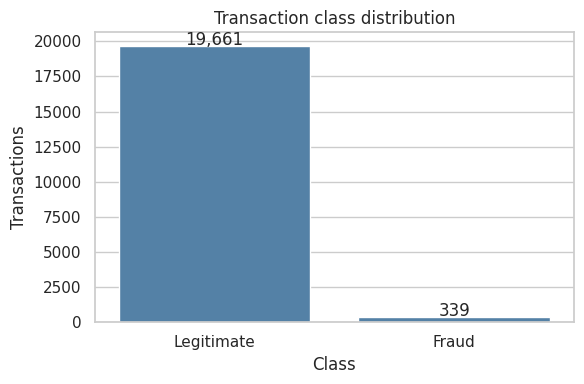

In [3]:
counts = df["is_fraud"].value_counts().reindex([0, 1])
class_table = pd.DataFrame({
    "Transactions": counts.to_numpy(),
    "Share (%)": (counts.to_numpy() / len(df) * 100).round(3)
}, index=["Legitimate (0)", "Fraud (1)"])
display(class_table)
print(f"Always-legitimate accuracy: {100 * counts[0] / len(df):.3f}%")

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=["Legitimate", "Fraud"], y=counts.to_numpy(), color="steelblue", ax=ax)
for index, count in enumerate(counts):
    ax.text(index, count + 100, f"{count:,}", ha="center")
ax.set(title="Transaction class distribution", xlabel="Class", ylabel="Transactions")
plt.tight_layout()
plt.show()

### Amounts, transaction behaviour and risk signals

We compare distributions for the two classes and inspect fraud rates at different CVV retry counts. These plots are exploratory; feature selection later uses training-fold SHAP values rather than the test set.

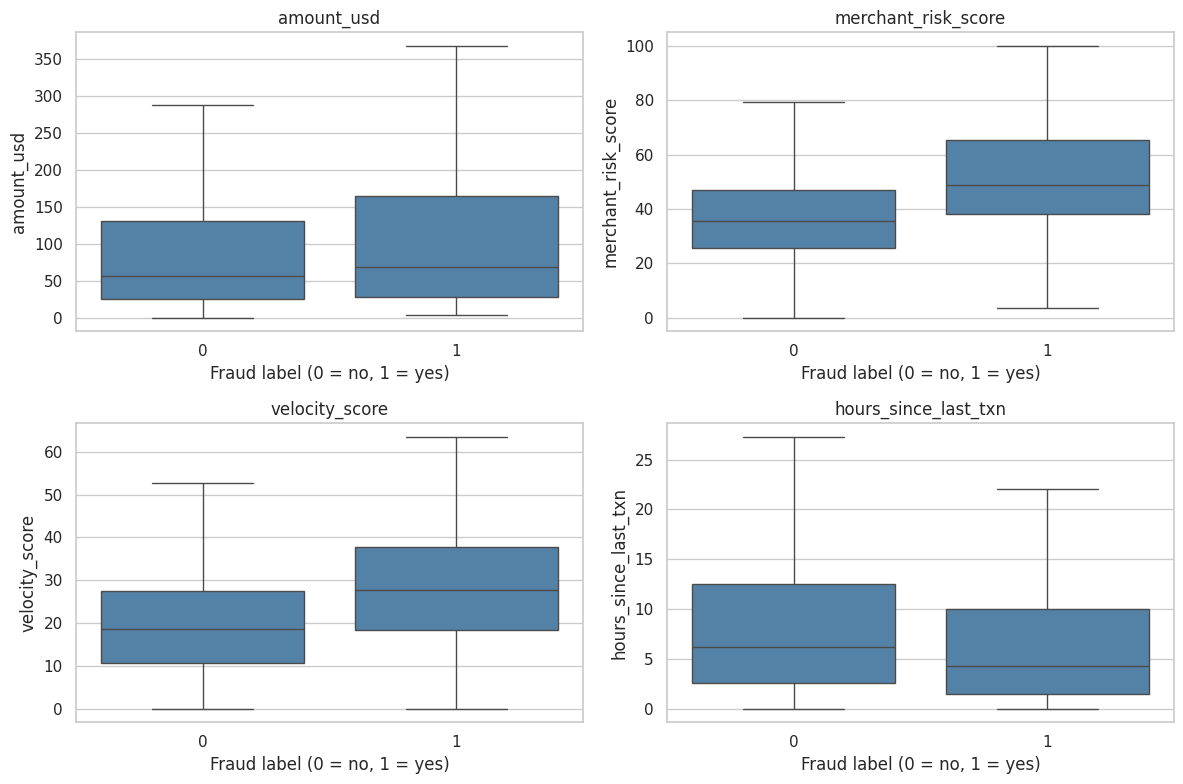

,amount_usd,merchant_risk_score,velocity_score,hours_since_last_txn,cvv_retry_count,txn_count_last_24h
is_fraud,,,,,,
0,57.35,35.5,18.7,6.23,0.0,3.0
1,69.77,48.7,27.7,4.27,1.0,4.0


In [4]:
eda_columns = ["amount_usd", "merchant_risk_score", "velocity_score", "hours_since_last_txn"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for axis, column in zip(axes.flat, eda_columns):
    sns.boxplot(data=df, x="is_fraud", y=column, showfliers=False, color="steelblue", ax=axis)
    axis.set(xlabel="Fraud label (0 = no, 1 = yes)", title=column)
plt.tight_layout()
plt.show()

display(df.groupby("is_fraud")[eda_columns + ["cvv_retry_count", "txn_count_last_24h"]].median().round(2))

,transactions,fraud_count,fraud_rate_pct
cvv_retry_count,,,
0,16658,153,0.92
1,3073,143,4.65
2,254,41,16.14
3,15,2,13.33


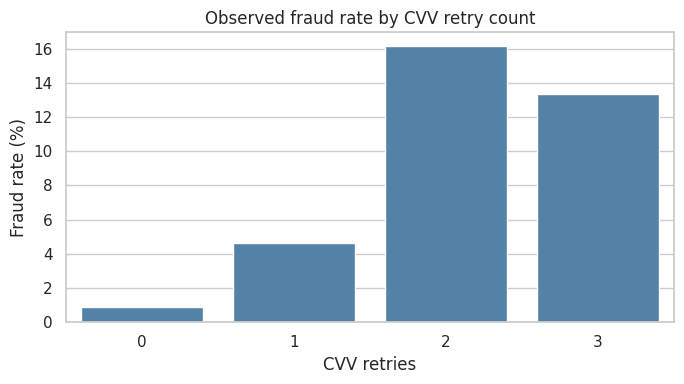

In [5]:
cvv_table = df.groupby("cvv_retry_count")["is_fraud"].agg(fraud_count="sum", transactions="count", fraud_rate="mean")
cvv_table["fraud_rate_pct"] = (cvv_table["fraud_rate"] * 100).round(2)
display(cvv_table[["transactions", "fraud_count", "fraud_rate_pct"]])

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=cvv_table.index, y=cvv_table["fraud_rate_pct"], color="steelblue", ax=ax)
ax.set(title="Observed fraud rate by CVV retry count", xlabel="CVV retries", ylabel="Fraud rate (%)")
plt.tight_layout()
plt.show()

### Categorical and numerical structure

The categorical fields have a small number of distinct values, so one-hot encoding is practical. A correlation plot summarizes linear relationships but is **not** used to remove predictors.

,Categories
merchant_category,12
device_type,8
card_type,5
auth_method,5
channel,5


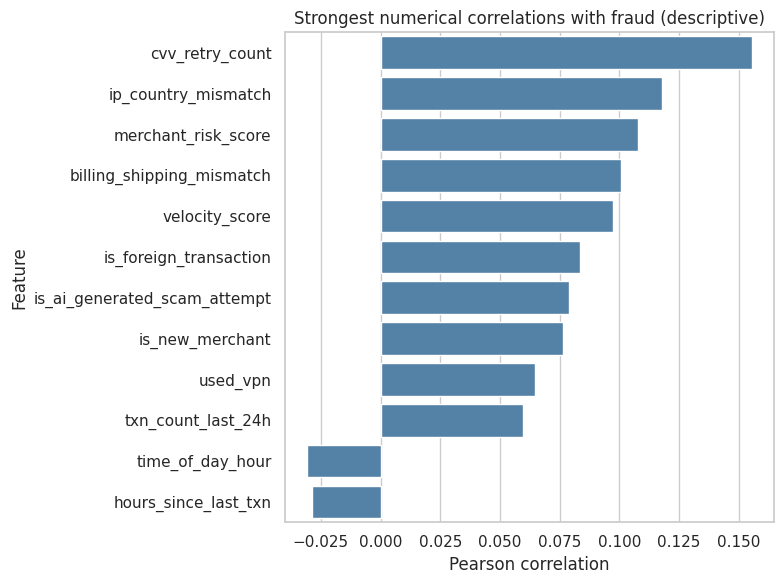

In [6]:
categorical_features = df.select_dtypes(include="object").columns.tolist()
display(pd.DataFrame({"Categories": df[categorical_features].nunique()}).sort_values("Categories", ascending=False))

numeric_corr = df.select_dtypes(include=["number", "bool"]).drop(columns="transaction_id").corr()
correlations = numeric_corr["is_fraud"].drop("is_fraud").sort_values(key=lambda series: series.abs(), ascending=False)
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=correlations.head(12).values, y=correlations.head(12).index, color="steelblue", ax=ax)
ax.set(title="Strongest numerical correlations with fraud (descriptive)", xlabel="Pearson correlation", ylabel="Feature")
plt.tight_layout()
plt.show()

## 2. Stratified hold-out and five-fold cross-validation

We reserve 20% for a final, untouched test set. Stratification preserves the rare fraud proportion. Five-fold CV takes place **only in the 80% training set** and supplies out-of-fold (OOF) probabilities for model comparison and threshold selection.

In [7]:
from sklearn.model_selection import train_test_split, StratifiedKFold

all_features = [c for c in df.columns if c not in ["transaction_id", "is_fraud"]]
X = df[all_features].copy()
y = df["is_fraud"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(skf.split(X_train, y_train))

split_summary = pd.DataFrame({
    "Subset": ["Training", "Test"],
    "Transactions": [len(y_train), len(y_test)],
    "Fraud": [int(y_train.sum()), int(y_test.sum())],
    "Fraud rate (%)": [100 * y_train.mean(), 100 * y_test.mean()]
})
display(split_summary.round(3))

display(pd.DataFrame([
    {
        "Fold": index + 1,
        "Train fraud": int(y_train.iloc[train_idx].sum()),
        "Validation fraud": int(y_train.iloc[val_idx].sum()),
        "Validation size": len(val_idx)
    }
    for index, (train_idx, val_idx) in enumerate(cv_splits)
]))

,Subset,Transactions,Fraud,Fraud rate (%)
0,Training,16000,271,1.694
1,Test,4000,68,1.700


,Fold,Train fraud,Validation fraud,Validation size
0,1,217,54,3200
1,2,217,54,3200
2,3,217,54,3200
3,4,217,54,3200
4,5,216,55,3200


### Preprocessing and imbalance treatment

We drop `transaction_id` because it is an identifier, not a behavioural predictor. The CSV contains no missing values, so imputation is unnecessary. Boolean flags remain numerical; categorical fields are one-hot encoded **within each fold** to prevent preprocessing leakage.

Only Logistic Regression receives numerical standardization, because its coefficients are sensitive to feature scale; the tree-based models do not require it. We avoid oversampling, which can create synthetic minority observations, and use the model-specific class weights chosen for the final configurations where applicable.

## 3. Model fitting on all original features

The following are the **final selected hyperparameter configurations** for each of the five requested models. The hyperparameter search itself is intentionally omitted. All models share the same splits and feature encodings for a fair comparison.

In [8]:
from sklearn.base import BaseEstimator
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_recall_curve,
    precision_score, recall_score, f1_score, accuracy_score, confusion_matrix
)
import shap

class CatBoostCompatible(CatBoostClassifier):
    def __sklearn_tags__(self):
        return BaseEstimator.__sklearn_tags__(self)

    def __sklearn_is_fitted__(self):
        return self.is_fitted()

MODEL_CONFIGS = {'Logistic Regression': {'C': 0.1, 'class_weight': None},
 'CatBoost': {'iterations': 450,
              'depth': 3,
              'learning_rate': 0.03,
              'l2_leaf_reg': 7,
              'auto_class_weights': None},
 'Random Forest': {'n_estimators': 250,
                   'max_depth': None,
                   'min_samples_leaf': 2,
                   'max_features': 'sqrt',
                   'class_weight': None},
 'XGBoost': {'n_estimators': 260,
             'max_depth': 2,
             'learning_rate': 0.06,
             'subsample': 0.9,
             'colsample_bytree': 0.9,
             'min_child_weight': 3,
             'reg_lambda': 5,
             'scale_pos_weight': 10},
 'LightGBM': {'n_estimators': 220,
              'num_leaves': 7,
              'learning_rate': 0.035,
              'min_child_samples': 30,
              'max_depth': 4,
              'reg_lambda': 5,
              'scale_pos_weight': 1}}

pd.DataFrame([
    {"Model": name, "Final configuration": str(params)}
    for name, params in MODEL_CONFIGS.items()
]).set_index("Model")

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Final configuration
Model,
Logistic Regression,"{'C': 0.1, 'class_weight': None}"
CatBoost,"{'iterations': 450, 'depth': 3, 'learning_rate..."
Random Forest,"{'n_estimators': 250, 'max_depth': None, 'min_..."
XGBoost,"{'n_estimators': 260, 'max_depth': 2, 'learnin..."
LightGBM,"{'n_estimators': 220, 'num_leaves': 7, 'learni..."


In [9]:
def build_pipeline(model_name, features):
    categories = [column for column in categorical_features if column in features]
    numerics = [column for column in features if column not in categories]
    numerical_step = StandardScaler() if model_name == "Logistic Regression" else "passthrough"
    transformer = ColumnTransformer(
        transformers=[
            ("numeric", numerical_step, numerics),
            ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categories)
        ],
        verbose_feature_names_out=False
    )
    options = MODEL_CONFIGS[model_name]
    if model_name == "Logistic Regression":
        estimator = LogisticRegression(max_iter=2000, solver="lbfgs", random_state=RANDOM_STATE, **options)
    elif model_name == "Random Forest":
        estimator = RandomForestClassifier(n_jobs=4, random_state=RANDOM_STATE, **options)
    elif model_name == "XGBoost":
        estimator = XGBClassifier(objective="binary:logistic", eval_metric="logloss", tree_method="hist", n_jobs=4, random_state=RANDOM_STATE, **options)
    elif model_name == "LightGBM":
        estimator = LGBMClassifier(n_jobs=4, random_state=RANDOM_STATE, verbosity=-1, **options)
    else:
        estimator = CatBoostCompatible(thread_count=4, random_seed=RANDOM_STATE, verbose=False, allow_writing_files=False, **options)
    return Pipeline([("preprocess", transformer), ("classifier", estimator)])

model_names = list(MODEL_CONFIGS)

def best_f1_threshold(labels, probabilities):
    precision, recall, thresholds = precision_recall_curve(labels, probabilities)
    f1_values = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    return float(thresholds[np.argmax(f1_values)])

def metric_row(labels, probabilities, threshold):
    predictions = (np.asarray(probabilities) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=[0, 1]).ravel()
    return {
        "Threshold": float(threshold),
        "Precision": precision_score(labels, predictions, zero_division=0),
        "Recall": recall_score(labels, predictions, zero_division=0),
        "F1": f1_score(labels, predictions, zero_division=0),
        "Average precision": average_precision_score(labels, probabilities),
        "ROC AUC": roc_auc_score(labels, probabilities),
        "Accuracy": accuracy_score(labels, predictions),
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn)
    }

### Cross-validated baseline results

A separate copy of each pipeline is fitted in every fold, and each row receives a prediction only from a model that did not train on it. We select a classification threshold from these OOF probabilities by maximizing training OOF F1; the test labels are not used.

In [10]:
baseline_oof = {}
fold_estimators = {}
cv_rows = []

for name in model_names:
    probabilities = np.empty(len(y_train), dtype=float)
    fold_estimators[name] = []
    for train_idx, val_idx in cv_splits:
        pipeline = build_pipeline(name, all_features)
        pipeline.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
        probabilities[val_idx] = pipeline.predict_proba(X_train.iloc[val_idx])[:, 1]
        fold_estimators[name].append(pipeline)
    baseline_oof[name] = probabilities
    threshold = best_f1_threshold(y_train, probabilities)
    cv_rows.append({"Model": name, "Feature set": "All features", **metric_row(y_train, probabilities, threshold)})

baseline_cv = pd.DataFrame(cv_rows).sort_values("F1", ascending=False)
display(baseline_cv[["Model", "Precision", "Recall", "F1", "Average precision", "ROC AUC", "Threshold"]].round(4))

,Model,Precision,Recall,F1,Average precision,ROC AUC,Threshold
0,Logistic Regression,0.4006,0.4982,0.4441,0.4171,0.9423,0.1715
3,XGBoost,0.3883,0.4428,0.4138,0.3599,0.9345,0.5512
1,CatBoost,0.4591,0.3727,0.4114,0.3673,0.9356,0.1633
4,LightGBM,0.3879,0.4022,0.3949,0.3297,0.9325,0.1594
2,Random Forest,0.3520,0.3948,0.3722,0.2734,0.9154,0.1240


## 4. SHAP interpretation and feature selection

SHAP estimates how strongly each input contributes to a prediction. We explain **Logistic Regression**, chosen in advance as a transparent SHAP reference, then sum the absolute SHAP contributions of one-hot columns back to each original field. This avoids treating categories as separate business features.

For explanation only, the sample includes extra fraud cases so the rare class is visible. This **does not alter training or evaluation data**. We keep the 12 highest-ranked original predictors as a prespecified, approximately half-size feature set.

Prespecified SHAP reference model: Logistic Regression
SHAP-selected original features: ['cvv_retry_count', 'auth_method', 'merchant_risk_score', 'velocity_score', 'is_new_merchant', 'ip_country_mismatch', 'is_foreign_transaction', 'merchant_category', 'used_vpn', 'billing_shipping_mismatch', 'time_of_day_hour', 'prior_disputes']


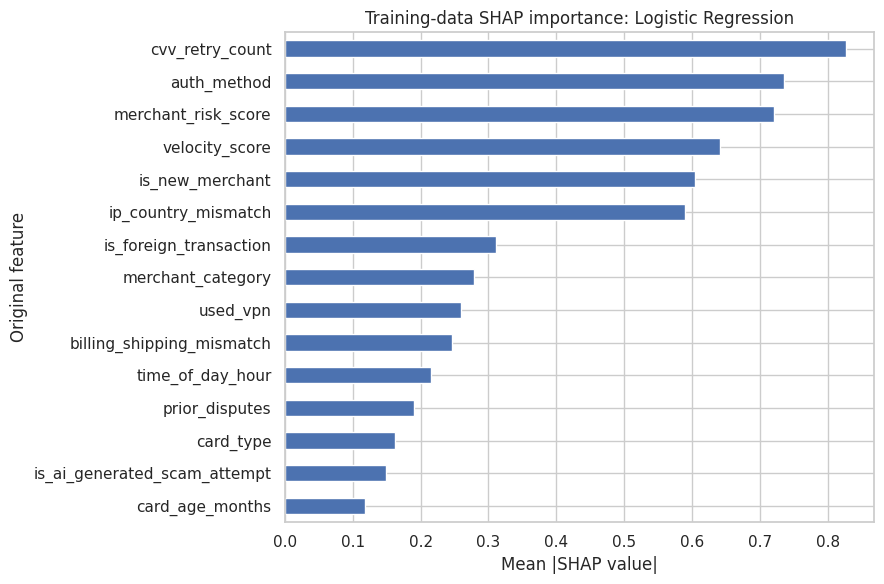

In [11]:
reference_name = "Logistic Regression"
print(f"Prespecified SHAP reference model: {reference_name}")

def explanation_sample(features, labels, n_fraud=50, n_legit=150, seed=42):
    selected_indices = []
    for label, count in [(1, n_fraud), (0, n_legit)]:
        choices = labels[labels == label].sample(n=min(count, int((labels == label).sum())), random_state=seed).index
        selected_indices.extend(choices)
    return features.loc[selected_indices].sample(frac=1, random_state=seed)

def raw_name(encoded_name, raw_features):
    if encoded_name in raw_features:
        return encoded_name
    return next(
        (column for column in sorted(raw_features, key=len, reverse=True) if encoded_name.startswith(column + "_")),
        encoded_name
    )

def shap_ranking(pipeline, sample):
    preprocess = pipeline.named_steps["preprocess"]
    classifier = pipeline.named_steps["classifier"]
    transformed = preprocess.transform(sample)
    if isinstance(classifier, LogisticRegression):
        explainer = shap.LinearExplainer(classifier, transformed[:min(100, len(transformed))])
        values = explainer(transformed).values
    else:
        values = shap.TreeExplainer(classifier).shap_values(transformed)
    if isinstance(values, list):
        values = values[-1]
    values = np.asarray(values)
    if values.ndim == 3:
        values = values[:, :, 1]
    encoded_names = preprocess.get_feature_names_out()
    raw_names = [raw_name(name, sample.columns) for name in encoded_names]
    grouped = pd.DataFrame({"Original feature": raw_names, "Mean absolute SHAP": np.abs(values).mean(axis=0)})
    return grouped.groupby("Original feature")["Mean absolute SHAP"].sum().sort_values(ascending=False)

reference_pipeline = build_pipeline(reference_name, all_features)
reference_pipeline.fit(X_train, y_train)
train_explanation_sample = explanation_sample(X_train, y_train, n_fraud=75, n_legit=225)
shap_scores = shap_ranking(reference_pipeline, train_explanation_sample)
selected_features = shap_scores.head(12).index.tolist()

print("SHAP-selected original features:", selected_features)
fig, ax = plt.subplots(figsize=(9, 6))
shap_scores.head(15).sort_values().plot.barh(ax=ax)
ax.set(title=f"Training-data SHAP importance: {reference_name}", xlabel="Mean |SHAP value|", ylabel="Original feature")
plt.tight_layout()
plt.show()

### Leakage-safe SHAP selection within cross-validation

To assess reduced-feature models fairly, each CV fold selects its own 12 features using **only that fold's training portion** and its already fitted reference model. The validation fold never influences feature selection. We then train all five reduced-feature models from scratch using those fold-specific columns.

In [12]:
fold_selected_features = []
for fold_number, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    fold_sample = explanation_sample(
        X_train.iloc[train_idx], y_train.iloc[train_idx],
        n_fraud=50, n_legit=150, seed=RANDOM_STATE + fold_number
    )
    scores = shap_ranking(fold_estimators[reference_name][fold_number - 1], fold_sample)
    fold_selected_features.append(scores.head(12).index.tolist())

fold_selection = pd.DataFrame({
    "Feature": all_features,
    "Selected in folds": [sum(feature in selected for selected in fold_selected_features) for feature in all_features]
}).sort_values(["Selected in folds", "Feature"], ascending=[False, True])
display(fold_selection.head(18))

,Feature,Selected in folds
3,auth_method,5
16,billing_shipping_mismatch,5
17,cvv_retry_count,5
15,ip_country_mismatch,5
6,is_foreign_transaction,5
13,is_new_merchant,5
1,merchant_category,5
22,merchant_risk_score,5
14,used_vpn,5
18,velocity_score,5


## 5. Model fitting after SHAP feature selection

The same five classifiers and tuned settings are refitted using the SHAP-selected columns. We compare the reduced and original-feature versions using the same CV folds and the same OOF threshold-selection rule.

In [13]:
selected_oof = {}
for name in model_names:
    probabilities = np.empty(len(y_train), dtype=float)
    for fold_number, (train_idx, val_idx) in enumerate(cv_splits):
        features = fold_selected_features[fold_number]
        pipeline = build_pipeline(name, features)
        pipeline.fit(X_train.iloc[train_idx][features], y_train.iloc[train_idx])
        probabilities[val_idx] = pipeline.predict_proba(X_train.iloc[val_idx][features])[:, 1]
    selected_oof[name] = probabilities
    threshold = best_f1_threshold(y_train, probabilities)
    cv_rows.append({"Model": name, "Feature set": "SHAP top 12", **metric_row(y_train, probabilities, threshold)})

cv_comparison = pd.DataFrame(cv_rows).sort_values(
    ["F1", "Average precision", "Recall", "Precision"], ascending=[False, False, False, False]
).reset_index(drop=True)
cv_comparison["Chosen"] = ""
cv_comparison.loc[0, "Chosen"] = "BEST"
champion_name = str(cv_comparison.loc[0, "Model"])
champion_featureset = str(cv_comparison.loc[0, "Feature set"])
print(f"Selected by training CV: {champion_name} ({champion_featureset})")
display(cv_comparison[["Chosen", "Model", "Feature set", "Precision", "Recall", "F1", "Average precision", "ROC AUC", "Threshold"]].round(4))

Selected by training CV: Logistic Regression (All features)


,Chosen,Model,Feature set,Precision,Recall,F1,Average precision,ROC AUC,Threshold
0,BEST,Logistic Regression,All features,0.4006,0.4982,0.4441,0.4171,0.9423,0.1715
1,,Logistic Regression,SHAP top 12,0.4737,0.3985,0.4329,0.3972,0.9420,0.2325
2,,XGBoost,All features,0.3883,0.4428,0.4138,0.3599,0.9345,0.5512
3,,CatBoost,All features,0.4591,0.3727,0.4114,0.3673,0.9356,0.1633
4,,CatBoost,SHAP top 12,0.3531,0.4613,0.4000,0.3512,0.9336,0.1269
5,,LightGBM,All features,0.3879,0.4022,0.3949,0.3297,0.9325,0.1594
6,,XGBoost,SHAP top 12,0.3733,0.4133,0.3923,0.3558,0.9369,0.5896
7,,LightGBM,SHAP top 12,0.3410,0.4354,0.3825,0.3380,0.9334,0.1421
8,,Random Forest,All features,0.3520,0.3948,0.3722,0.2734,0.9154,0.1240
9,,Random Forest,SHAP top 12,0.2615,0.4834,0.3394,0.2418,0.9143,0.1216


### Variation between validation folds

Because each fold has only about 54 fraud cases, scores can change between folds. We report mean and standard deviation to show this uncertainty rather than relying solely on the pooled OOF score.

In [14]:
fold_rows = []
for _, record in cv_comparison.iterrows():
    name = record["Model"]
    feature_set = record["Feature set"]
    probabilities = baseline_oof[name] if feature_set == "All features" else selected_oof[name]
    threshold = float(record["Threshold"])
    fold_f1 = []
    fold_ap = []
    for train_idx, val_idx in cv_splits:
        truth = y_train.iloc[val_idx]
        fold_scores = probabilities[val_idx]
        fold_ap.append(average_precision_score(truth, fold_scores))
        fold_f1.append(f1_score(truth, (fold_scores >= threshold).astype(int), zero_division=0))
    fold_rows.append({
        "Model": name, "Feature set": feature_set,
        "Mean fold F1": np.mean(fold_f1), "SD fold F1": np.std(fold_f1, ddof=1),
        "Mean fold AP": np.mean(fold_ap), "SD fold AP": np.std(fold_ap, ddof=1)
    })
fold_stability = pd.DataFrame(fold_rows)
display(fold_stability.round(4))

,Model,Feature set,Mean fold F1,SD fold F1,Mean fold AP,SD fold AP
0,Logistic Regression,All features,0.4461,0.0516,0.4242,0.0817
1,Logistic Regression,SHAP top 12,0.4335,0.0683,0.4063,0.0754
2,XGBoost,All features,0.4138,0.0958,0.3721,0.1243
3,CatBoost,All features,0.4093,0.0777,0.3758,0.0861
4,CatBoost,SHAP top 12,0.4017,0.0624,0.3577,0.0766
5,LightGBM,All features,0.3943,0.0756,0.3478,0.1180
6,XGBoost,SHAP top 12,0.3923,0.0949,0.3615,0.1003
7,LightGBM,SHAP top 12,0.3818,0.0724,0.3524,0.1034
8,Random Forest,All features,0.3745,0.0797,0.2896,0.0736
9,Random Forest,SHAP top 12,0.3407,0.0362,0.2670,0.0666


## 6. Evaluation and comparative results

**Decision rule:** the single winner is the model-and-feature-set combination with the highest OOF F1 score, followed by average precision, recall and precision to break ties. F1 balances fraud detection (recall) against false alarms (precision). Average precision assesses ranking quality across thresholds, and ROC AUC is supplementary.

The winner is fixed **before looking at test labels**. Because the OOF thresholds are chosen using those same OOF predictions, the training F1 estimates can be mildly optimistic; the untouched test result provides the independent check. All ten fitted variants are subsequently trained on the entire training partition and evaluated once on the untouched test set. The final reduced model uses the SHAP ranking computed on the full training set.

In [15]:
test_rows = []
test_probabilities = {}
final_estimators = {}

for name in model_names:
    for feature_set, features in [("All features", all_features), ("SHAP top 12", selected_features)]:
        pipeline = build_pipeline(name, features)
        pipeline.fit(X_train[features], y_train)
        probability = pipeline.predict_proba(X_test[features])[:, 1]
        training_record = cv_comparison.loc[
            (cv_comparison["Model"] == name) & (cv_comparison["Feature set"] == feature_set)
        ].iloc[0]
        threshold = float(training_record["Threshold"])
        result = {"Model": name, "Feature set": feature_set, **metric_row(y_test, probability, threshold)}
        result["Chosen"] = "BEST" if (name, feature_set) == (champion_name, champion_featureset) else ""
        test_rows.append(result)
        test_probabilities[(name, feature_set)] = probability
        final_estimators[(name, feature_set)] = pipeline

test_comparison = pd.DataFrame(test_rows)
cv_order = cv_comparison[["Model", "Feature set"]].assign(CV_rank=np.arange(1, len(cv_comparison) + 1))
test_comparison = test_comparison.merge(cv_order, on=["Model", "Feature set"]).sort_values("CV_rank")
display(test_comparison[["Chosen", "Model", "Feature set", "Precision", "Recall", "F1", "Average precision", "ROC AUC", "Accuracy", "TP", "FP", "FN"]].round(4))

,Chosen,Model,Feature set,Precision,Recall,F1,Average precision,ROC AUC,Accuracy,TP,FP,FN
0,BEST,Logistic Regression,All features,0.4177,0.4853,0.4490,0.4865,0.9523,0.9798,33,46,35
1,,Logistic Regression,SHAP top 12,0.4808,0.3676,0.4167,0.4012,0.9388,0.9825,25,27,43
6,,XGBoost,All features,0.4000,0.4706,0.4324,0.3931,0.9368,0.9790,32,48,36
2,,CatBoost,All features,0.5098,0.3824,0.4370,0.4233,0.9382,0.9832,26,25,42
3,,CatBoost,SHAP top 12,0.3690,0.4559,0.4079,0.3688,0.9292,0.9775,31,53,37
8,,LightGBM,All features,0.4308,0.4118,0.4211,0.3812,0.9351,0.9808,28,37,40
7,,XGBoost,SHAP top 12,0.3562,0.3824,0.3688,0.3490,0.9292,0.9778,26,47,42
9,,LightGBM,SHAP top 12,0.3294,0.4118,0.3660,0.3364,0.9262,0.9758,28,57,40
4,,Random Forest,All features,0.3188,0.3235,0.3212,0.2640,0.9244,0.9768,22,47,46
5,,Random Forest,SHAP top 12,0.2314,0.4118,0.2963,0.2661,0.9032,0.9668,28,93,40


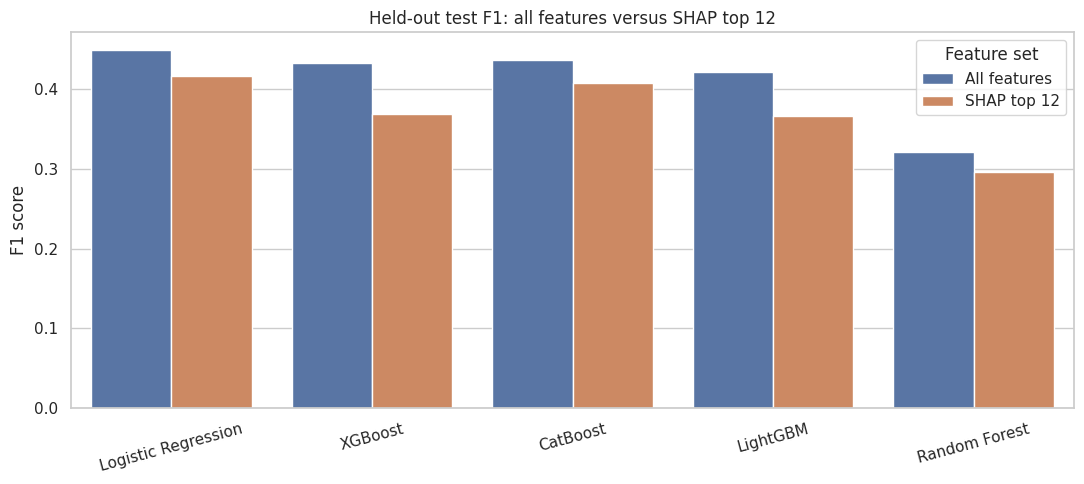

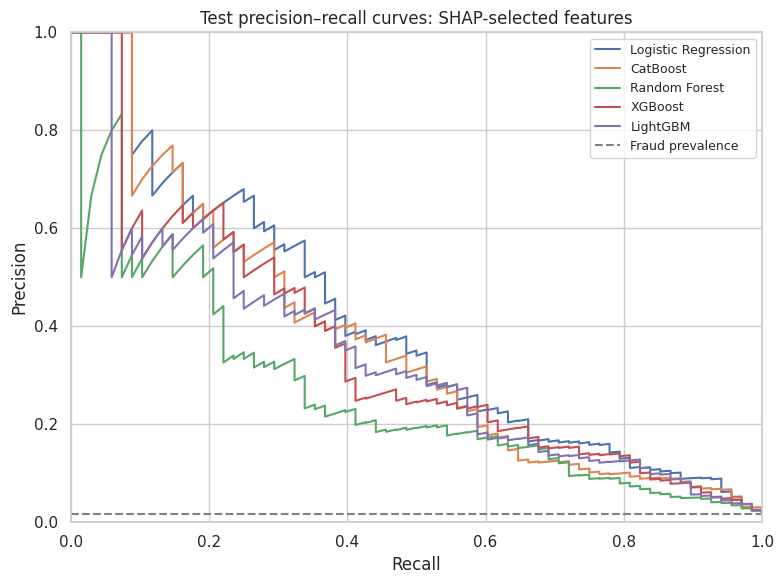

In [16]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=test_comparison, x="Model", y="F1", hue="Feature set", palette="deep", ax=ax)
ax.set(title="Held-out test F1: all features versus SHAP top 12", ylabel="F1 score", xlabel="")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
for name in model_names:
    p, r, _ = precision_recall_curve(y_test, test_probabilities[(name, "SHAP top 12")])
    ax.plot(r, p, label=name)
ax.axhline(y_test.mean(), linestyle="--", color="gray", label="Fraud prevalence")
ax.set(title="Test precision–recall curves: SHAP-selected features", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

### The selected model and its errors

The confusion matrix reports true negatives, false alarms, missed frauds and detected frauds at the threshold learned from training folds. A high F1 should never obscure the absolute number of missed fraudulent transactions.

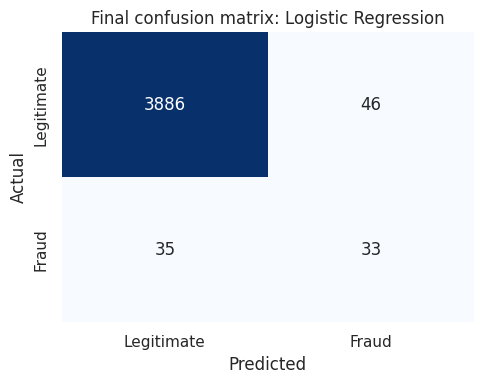

FINAL SELECTION: Logistic Regression | All features
Training OOF F1: 0.444 | OOF average precision: 0.417
Test precision: 0.418 | Recall: 0.485 | F1: 0.449
Test average precision: 0.486 | ROC AUC: 0.952
Detected frauds: 33 | Missed frauds: 35 | False alerts: 46
Decision threshold (chosen from training OOF predictions): 0.1715


In [17]:
best_test = test_comparison.loc[
    (test_comparison["Model"] == champion_name) &
    (test_comparison["Feature set"] == champion_featureset)
].iloc[0]
threshold = float(best_test["Threshold"])
champion_probs = test_probabilities[(champion_name, champion_featureset)]
champion_predictions = (champion_probs >= threshold).astype(int)

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, champion_predictions, labels=[0, 1]),
            annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Legitimate", "Fraud"], yticklabels=["Legitimate", "Fraud"])
ax.set(title=f"Final confusion matrix: {champion_name}", xlabel="Predicted", ylabel="Actual")
plt.tight_layout()
plt.show()

best_cv = cv_comparison.iloc[0]
print(f"FINAL SELECTION: {champion_name} | {champion_featureset}")
print(f"Training OOF F1: {best_cv['F1']:.3f} | OOF average precision: {best_cv['Average precision']:.3f}")
print(f"Test precision: {best_test['Precision']:.3f} | Recall: {best_test['Recall']:.3f} | F1: {best_test['F1']:.3f}")
print(f"Test average precision: {best_test['Average precision']:.3f} | ROC AUC: {best_test['ROC AUC']:.3f}")
print(f"Detected frauds: {int(best_test['TP'])} | Missed frauds: {int(best_test['FN'])} | False alerts: {int(best_test['FP'])}")
print(f"Decision threshold (chosen from training OOF predictions): {threshold:.4f}")

### Interpretation and limitations

**Logistic Regression with all 24 original predictors is the single selected model.** It earned the highest training OOF F1 (**0.444**) and OOF average precision (**0.417**). On the untouched test set, its precision is **0.418**, recall **0.485**, F1 **0.449**, average precision **0.486**, and ROC AUC **0.952**. It detected **33 of 68 fraudulent transactions**, missed **35**, and raised **46 false alerts**.

CatBoost achieves higher test precision (**0.510**) but lower recall (**0.382**), while XGBoost catches nearly as many fraud cases but has a lower test F1 (**0.432**). Reducing Logistic Regression to 12 SHAP features decreased its training OOF F1 from **0.444 to 0.433** and test F1 from **0.449 to 0.417**. The full-feature model therefore retains the best balance for the declared metric.

This is a small, highly imbalanced, synthetic dataset. Its fraud rate and class relationships may not reflect real transactions. Features such as `is_ai_generated_scam_attempt` must be checked for availability **at transaction time** before any real deployment. Different costs for missed fraud and false alarms would require an operational threshold and metric choice.